# 🧠 Dual-Branch Hybrid Model: DenseNet121 + Vision Transformer with Cross-Attention Fusion

## Architecture Overview
```
Branch 1 → DenseNet121 (CNN-based local feature extractor)
Branch 2 → Vision Transformer (global self-attention feature extractor)
               ↓
    Cross-Attention Fusion Layer
               ↓
       Feature Selection (SE-style gating)
               ↓
     Multi-class Classifier (4 classes)
```

### Key Design Decisions
| Component | Choice | Rationale |
|-----------|--------|-----------|
| Branch 1  | DenseNet121 | Dense skip connections → strong local texture/edge features |
| Branch 2  | ViT (patch-based) | Long-range global dependencies via self-attention |
| Fusion    | Cross-Attention | CNN queries ViT keys/values, enabling complementary fusion |
| Selection | Squeeze-Excitation Gate | Channel-wise recalibration of fused features |
| Output    | Softmax (4-class) | Multi-class classification |

## 1. Install & Import Dependencies

In [ ]:
# ── Install required packages ─────────────────────────────────────────────────
!pip install tensorflow matplotlib seaborn scikit-learn numpy pandas -q

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
import itertools

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {tf.config.list_physical_devices('GPU')}")

TensorFlow version : 2.10.0
GPUs available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuration — Edit These Before Running

In [2]:
# ══════════════════════════════════════════════════════════════════════════════
#  CONFIGURATION  ← Edit paths and hyperparameters here
# ══════════════════════════════════════════════════════════════════════════════

DATA_DIR        = "E:AL/alz/Final_Journal_Simulation/Dataset/ADNI/Final_Dataset/Enhanced_Augmented_6_Class (Different Variations)/AD vs CN vs EMCI vs LMCI/"        # Root dir: must contain one sub-folder per class
IMG_SIZE        = (224, 224)        # Input resolution (H, W)
PATCH_SIZE      = 16                # ViT patch size in pixels
NUM_CLASSES     = 4                 # Number of output classes
BATCH_SIZE      = 16
EPOCHS          = 50
LEARNING_RATE   = 1e-4
DROPOUT_RATE    = 0.3
VAL_SPLIT       = 0.2              # 20 % held out for validation
TEST_SPLIT      = 0.1              # 10 % held out for final test
PROJ_DIM        = 256              # Shared projection dimension
NUM_HEADS       = 8                # Multi-head attention heads
CHECKPOINT_PATH = 'best_model.h5'

CLASS_NAMES = None  # Set to e.g. ['cat','dog','bird','fish'] or leave None (auto)

print("Configuration loaded ✓")
print(f"  Data dir  : {DATA_DIR}")
print(f"  Image size: {IMG_SIZE}")
print(f"  Classes   : {NUM_CLASSES}")
print(f"  Batch     : {BATCH_SIZE}  |  Epochs: {EPOCHS}")

Configuration loaded ✓
  Data dir  : E:AL/alz/Final_Journal_Simulation/Dataset/ADNI/Final_Dataset/Enhanced_Augmented_6_Class (Different Variations)/AD vs CN vs EMCI vs LMCI/
  Image size: (224, 224)
  Classes   : 4
  Batch     : 16  |  Epochs: 50


## 3. Dataset Loading & Exploration

In [3]:
# ── Discover class folders ────────────────────────────────────────────────────
class_dirs = sorted([
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
])

if CLASS_NAMES is None:
    CLASS_NAMES = class_dirs

assert len(CLASS_NAMES) == NUM_CLASSES, (
    f"Found {len(CLASS_NAMES)} classes but NUM_CLASSES={NUM_CLASSES}. "
    "Update NUM_CLASSES in the config cell."
)

# ── Count images per class ────────────────────────────────────────────────────
class_counts = {}
all_paths, all_labels = [], []
VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

for idx, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, cls)
    files  = [
        f for f in os.listdir(folder)
        if os.path.splitext(f)[1].lower() in VALID_EXT
    ]
    class_counts[cls] = len(files)
    for f in files:
        all_paths.append(os.path.join(folder, f))
        all_labels.append(idx)

print(f"Total images: {len(all_paths)}")
for cls, cnt in class_counts.items():
    print(f"  {cls:25s}: {cnt:5d} images")

Total images: 40000
  AD                       : 10000 images
  CN                       : 10000 images
  EMCI                     : 10000 images
  LMCI                     : 10000 images


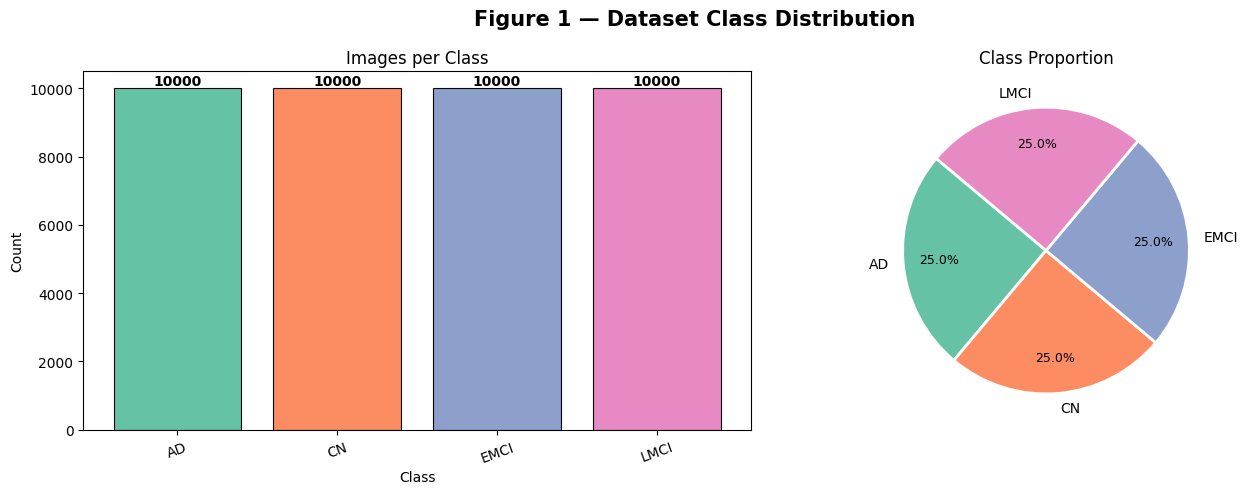

In [4]:
# ── Figure 1: Class Distribution Bar Chart ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Figure 1 — Dataset Class Distribution', fontsize=15, fontweight='bold')

colors = sns.color_palette('Set2', NUM_CLASSES)

# Bar chart
bars = axes[0].bar(CLASS_NAMES, class_counts.values(), color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Images per Class', fontsize=12)
axes[0].set_xlabel('Class', fontsize=10)
axes[0].set_ylabel('Count', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, class_counts.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Pie chart
wedges, texts, autotexts = axes[1].pie(
    class_counts.values(), labels=CLASS_NAMES, autopct='%1.1f%%',
    colors=colors, startangle=140, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(9)
axes[1].set_title('Class Proportion', fontsize=12)

plt.tight_layout()
plt.savefig('fig1_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

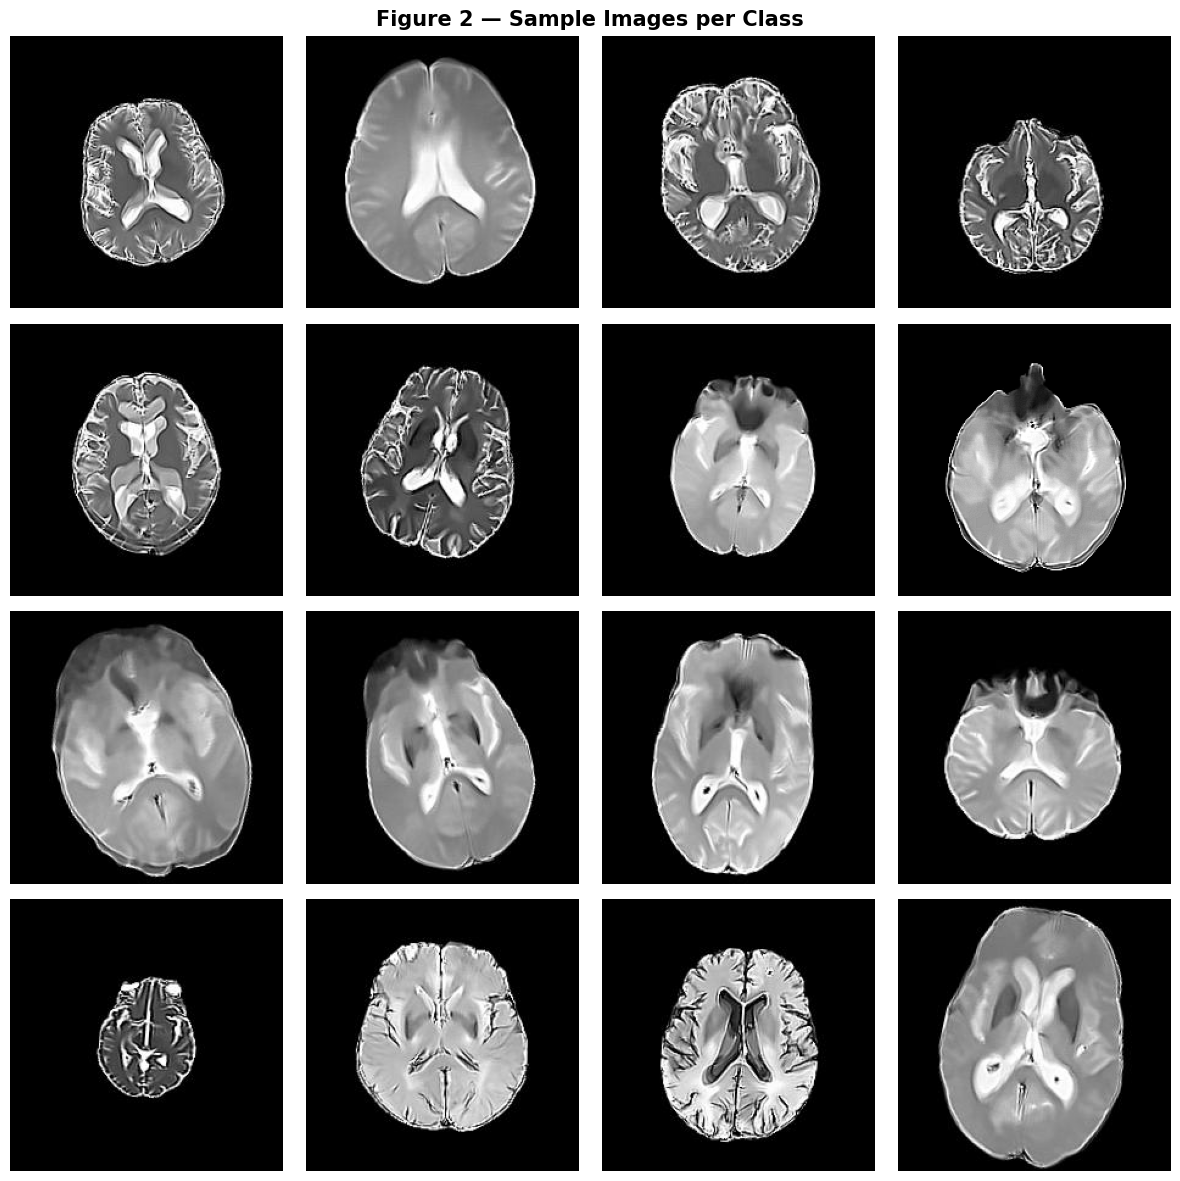

In [5]:
# ── Figure 2: Sample Images Grid (4 classes × 4 samples) ─────────────────────
from tensorflow.keras.preprocessing.image import load_img, img_to_array

N_SAMPLES = 4
fig, axes = plt.subplots(NUM_CLASSES, N_SAMPLES, figsize=(N_SAMPLES * 3, NUM_CLASSES * 3))
fig.suptitle('Figure 2 — Sample Images per Class', fontsize=15, fontweight='bold')

for row, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, cls)
    files  = [f for f in os.listdir(folder) if os.path.splitext(f)[1].lower() in VALID_EXT]
    sampled = np.random.choice(files, min(N_SAMPLES, len(files)), replace=False)
    for col, fname in enumerate(sampled):
        img = load_img(os.path.join(folder, fname), target_size=IMG_SIZE)
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(cls, fontsize=11, fontweight='bold', rotation=90,
                                       labelpad=10, va='center')
            axes[row, col].yaxis.set_label_coords(-0.15, 0.5)

plt.tight_layout()
plt.savefig('fig2_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Train / Validation / Test Split

In [6]:
# ── Stratified splits ─────────────────────────────────────────────────────────
all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)

# Step 1: hold out test set
X_temp, X_test, y_temp, y_test = train_test_split(
    all_paths, all_labels,
    test_size=TEST_SPLIT,
    stratify=all_labels,
    random_state=SEED
)

# Step 2: split remaining into train / val
val_ratio = VAL_SPLIT / (1 - TEST_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=val_ratio,
    stratify=y_temp,
    random_state=SEED
)

print(f"Train : {len(X_train):5d} images")
print(f"Val   : {len(X_val):5d} images")
print(f"Test  : {len(X_test):5d} images")

Train : 27999 images
Val   :  8001 images
Test  :  4000 images


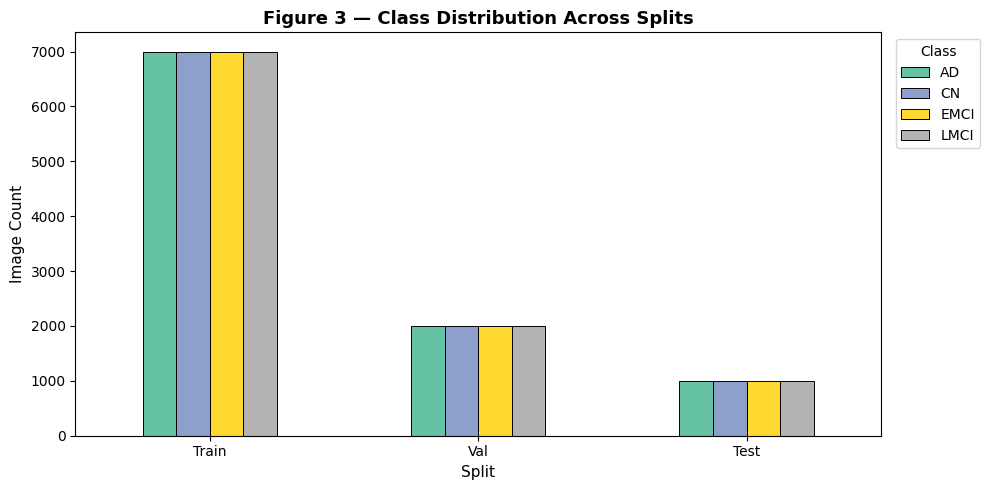

In [7]:
# ── Figure 3: Split Distribution ──────────────────────────────────────────────
split_data = {
    'Train': dict(zip(CLASS_NAMES, [np.sum(y_train == i) for i in range(NUM_CLASSES)])),
    'Val'  : dict(zip(CLASS_NAMES, [np.sum(y_val   == i) for i in range(NUM_CLASSES)])),
    'Test' : dict(zip(CLASS_NAMES, [np.sum(y_test  == i) for i in range(NUM_CLASSES)])),
}
df_split = pd.DataFrame(split_data).T

fig, ax = plt.subplots(figsize=(10, 5))
df_split.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black', linewidth=0.7)
ax.set_title('Figure 3 — Class Distribution Across Splits', fontsize=13, fontweight='bold')
ax.set_xlabel('Split', fontsize=11)
ax.set_ylabel('Image Count', fontsize=11)
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Class', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig3_split_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Data Pipeline (tf.data)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(path, label):
    """Load an image from disk and normalise to [0, 1]."""
    raw   = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment(image, label):
    """Apply random augmentation (training only)."""
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.8, 1.2)
    image = tf.image.random_hue(image, 0.05)
    # Random rotation via map_fn (±15°)
    angle = tf.random.uniform([], -0.26, 0.26)           # radians
    image = tf.keras.layers.RandomRotation(0.04)(image[tf.newaxis])[0]
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

def make_dataset(paths, labels, augment_fn=None, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    if augment_fn:
        ds = ds.map(augment_fn, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, augment_fn=augment, shuffle=True)
val_ds   = make_dataset(X_val,   y_val)
test_ds  = make_dataset(X_test,  y_test)

print("Datasets created ✓")
print(f"  Train batches : {len(train_ds)}")
print(f"  Val batches   : {len(val_ds)}")
print(f"  Test batches  : {len(test_ds)}")

Datasets created ✓
  Train batches : 1750
  Val batches   : 501
  Test batches  : 250


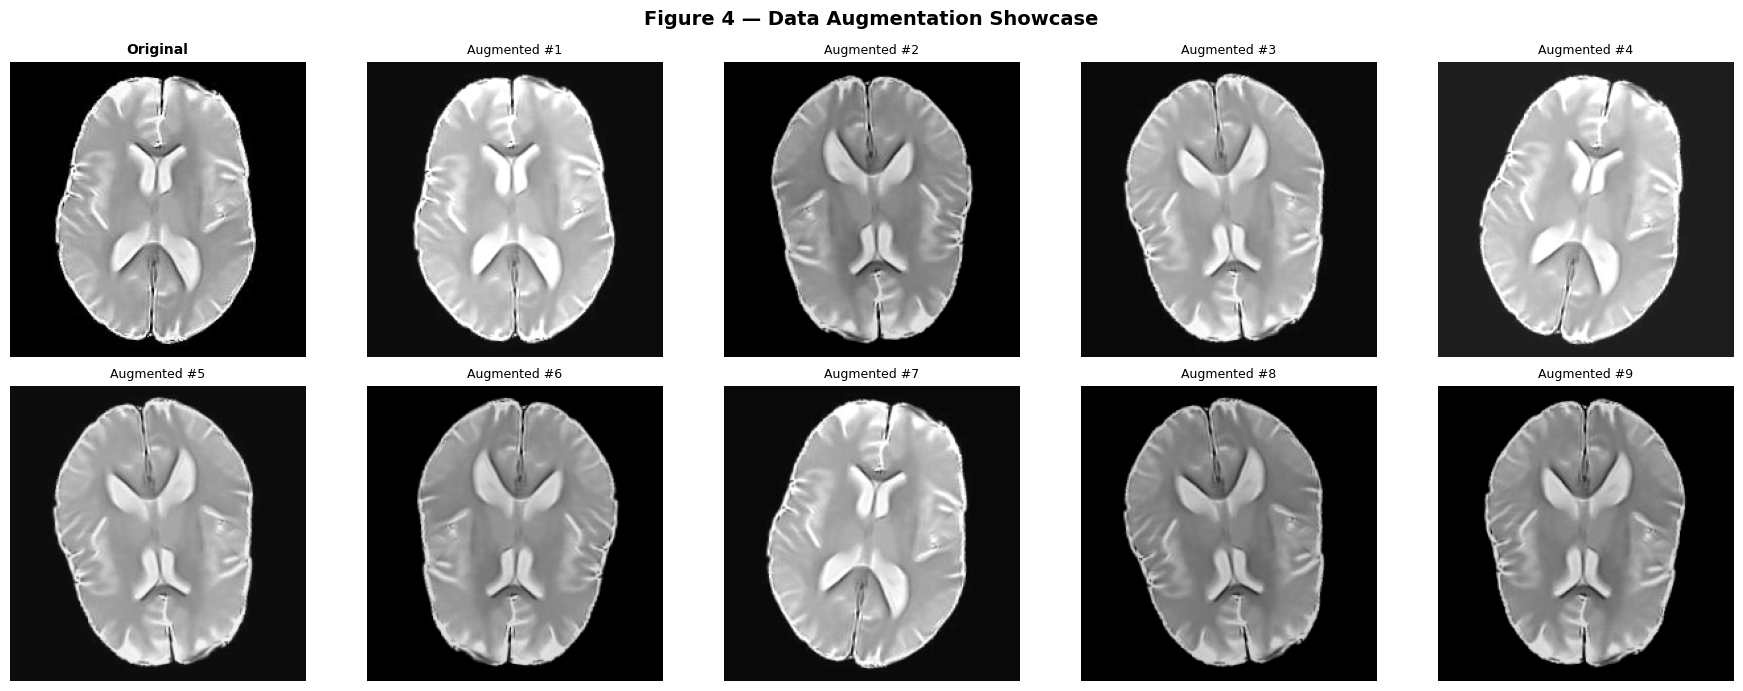

In [9]:
# ── Figure 4: Augmentation Showcase ───────────────────────────────────────────
sample_img_path = X_train[0]
raw    = tf.io.read_file(sample_img_path)
orig   = tf.image.decode_image(raw, channels=3, expand_animations=False)
orig   = tf.image.resize(orig, IMG_SIZE)
orig   = tf.cast(orig, tf.float32) / 255.0

n_aug  = 8
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle('Figure 4 — Data Augmentation Showcase', fontsize=14, fontweight='bold')

axes[0, 0].imshow(orig.numpy())
axes[0, 0].set_title('Original', fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

for i, ax in enumerate(axes.flat[1:]):
    aug_img, _ = augment(orig, 0)
    ax.imshow(aug_img.numpy())
    ax.set_title(f'Augmented #{i+1}', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('fig4_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Architecture — Building Blocks

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
#  6.1  BRANCH 1 — DenseNet121 Feature Extractor
# ══════════════════════════════════════════════════════════════════════════════

def build_densenet_branch(input_tensor, proj_dim=PROJ_DIM):
    """
    Loads DenseNet121 (ImageNet weights) as a frozen backbone.
    Extracts features from the last conv layer, applies global average pooling,
    then projects to `proj_dim` dimensions.

    Returns
    -------
    projected : Tensor  shape (B, proj_dim)
    spatial   : Tensor  shape (B, H*W, C)  — kept for cross-attention
    """
    base = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_tensor=input_tensor
    )
    # Freeze backbone weights
    base.trainable = False

    feat_map = base.output              # (B, H, W, C)
    B, H, W, C = feat_map.shape

    # Spatial features for cross-attention  →  (B, H*W, C)
    spatial = layers.Reshape((H * W, C))(feat_map)
    spatial = layers.Dense(proj_dim, use_bias=False)(spatial)   # (B, H*W, proj_dim)
    spatial = layers.LayerNormalization()(spatial)

    # Global pooled representation  →  (B, proj_dim)
    pooled     = layers.GlobalAveragePooling2D()(feat_map)      # (B, C)
    projected  = layers.Dense(proj_dim, activation='relu')(pooled)
    projected  = layers.LayerNormalization()(projected)

    return projected, spatial, base

print("DenseNet121 branch builder defined ✓")

DenseNet121 branch builder defined ✓


In [11]:
# ══════════════════════════════════════════════════════════════════════════════
#  6.2  BRANCH 2 — Vision Transformer (ViT) Feature Extractor
# ══════════════════════════════════════════════════════════════════════════════

# class PatchEmbedding(layers.Layer):
#     """
#     Splits an image into non-overlapping patches and linearly projects each
#     patch to `embed_dim` dimensions.  Adds learned positional embeddings.

#     Parameters
#     ----------
#     patch_size : int   — side length of each square patch (pixels)
#     embed_dim  : int   — embedding dimension (= proj_dim)
#     """

#     def __init__(self, patch_size, embed_dim, **kwargs):
#         super().__init__(**kwargs)
#         self.patch_size = patch_size
#         self.embed_dim  = embed_dim
#         self.proj       = layers.Dense(embed_dim)

#     def build(self, input_shape):
#         _, H, W, _ = input_shape
#         n_patches   = (H // self.patch_size) * (W // self.patch_size)
#         self.pos_emb = self.add_weight(
#             name='pos_emb',
#             shape=(1, n_patches, self.embed_dim),
#             initializer='random_normal',
#             trainable=True
#         )

#     def call(self, x):
#         B   = tf.shape(x)[0]
#         H, W = x.shape[1], x.shape[2]
#         p   = self.patch_size
#         # Reshape: (B, n_h, p, n_w, p, C) → (B, n_patches, p*p*C)
#         x   = tf.image.extract_patches(
#             images=x,
#             sizes=[1, p, p, 1],
#             strides=[1, p, p, 1],
#             rates=[1, 1, 1, 1],
#             padding='VALID'
#         )                             # (B, n_h, n_w, p*p*C)
#         n_h, n_w = x.shape[1], x.shape[2]
#         x   = tf.reshape(x, [B, n_h * n_w, -1])   # (B, n_patches, p*p*C)
#         x   = self.proj(x)                          # (B, n_patches, embed_dim)
#         x   = x + self.pos_emb
#         return x


# class PatchEmbedding(tf.keras.layers.Layer):
#     def __init__(self, patch_size, embed_dim):
#         super().__init__()

#         self.patch_size = patch_size
#         self.embed_dim = embed_dim

#         self.proj = layers.Dense(embed_dim)

#     def build(self, input_shape):

#         self.channels = input_shape[-1]

#         self.num_patches_h = input_shape[1] // self.patch_size
#         self.num_patches_w = input_shape[2] // self.patch_size

#         self.num_patches = self.num_patches_h * self.num_patches_w

#         self.patch_dim = self.patch_size * self.patch_size * self.channels

#         self.pos_emb = self.add_weight(
#             name="pos_emb",
#             shape=(1, self.num_patches, self.embed_dim),
#             initializer="random_normal",
#             trainable=True
#         )

#     def call(self, x):

#         B = tf.shape(x)[0]

#         patches = tf.image.extract_patches(
#             images=x,
#             sizes=[1, self.patch_size, self.patch_size, 1],
#             strides=[1, self.patch_size, self.patch_size, 1],
#             rates=[1, 1, 1, 1],
#             padding='VALID'
#         )

#         # IMPORTANT FIX
#         patches = tf.reshape(
#             patches,
#             [B, self.num_patches, self.patch_dim]
#         )

#         x = self.proj(patches)

#         x = x + self.pos_emb

#         return x

class PatchEmbedding(layers.Layer):

    def __init__(self, patch_size, embed_dim, **kwargs):
        super().__init__(**kwargs)

        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.proj = layers.Conv2D(
            filters=embed_dim,
            kernel_size=patch_size,
            strides=patch_size,
            padding='valid'
        )

    def build(self, input_shape):

        num_patches = (
            (input_shape[1] // self.patch_size) *
            (input_shape[2] // self.patch_size)
        )

        self.pos_emb = self.add_weight(
            name='pos_emb',
            shape=(1, num_patches, self.embed_dim),
            initializer='random_normal',
            trainable=True
        )

    def call(self, x):

        x = self.proj(x)

        B = tf.shape(x)[0]

        x = tf.reshape(
            x,
            [B, -1, self.embed_dim]
        )

        x = x + self.pos_emb

        return x

    def get_config(self):

        config = super().get_config()

        config.update({
            "patch_size": self.patch_size,
            "embed_dim": self.embed_dim,
        })

        return config

# class TransformerBlock(layers.Layer):
#     """
#     Standard Transformer encoder block:
#       LayerNorm → Multi-Head Self-Attention → Residual
#       LayerNorm → MLP (expand 4× then contract) → Residual

#     Parameters
#     ----------
#     embed_dim  : int  — token dimension
#     num_heads  : int  — attention heads
#     mlp_ratio  : int  — hidden dim = embed_dim × mlp_ratio
#     dropout    : float
#     """

#     def __init__(self, embed_dim, num_heads, mlp_ratio=4, dropout=0.1, **kwargs):
#         super().__init__(**kwargs)
#         self.norm1 = layers.LayerNormalization(epsilon=1e-6)
#         self.attn  = layers.MultiHeadAttention(
#             num_heads=num_heads, key_dim=embed_dim // num_heads,
#             dropout=dropout
#         )
#         self.norm2 = layers.LayerNormalization(epsilon=1e-6)
#         self.mlp   = keras.Sequential([
#             layers.Dense(embed_dim * mlp_ratio, activation='gelu'),
#             layers.Dropout(dropout),
#             layers.Dense(embed_dim),
#             layers.Dropout(dropout),
#         ])

#     def call(self, x, training=False):
#         x = x + self.attn(self.norm1(x), self.norm1(x), training=training)
#         x = x + self.mlp(self.norm2(x),  training=training)
#         return x

class TransformerBlock(layers.Layer):
    """
    Standard Transformer encoder block:
      LayerNorm → Multi-Head Self-Attention → Residual
      LayerNorm → MLP → Residual
    """

    def __init__(
        self,
        embed_dim,
        num_heads,
        mlp_ratio=4,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        # SAVE PARAMETERS
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.mlp_ratio = mlp_ratio
        self.dropout_rate = dropout

        # Layers
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)

        self.attn = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.mlp = keras.Sequential([
            layers.Dense(embed_dim * mlp_ratio, activation='gelu'),
            layers.Dropout(dropout),
            layers.Dense(embed_dim),
            layers.Dropout(dropout),
        ])

    def call(self, x, training=False):

        x = x + self.attn(
            self.norm1(x),
            self.norm1(x),
            training=training
        )

        x = x + self.mlp(
            self.norm2(x),
            training=training
        )

        return x

    def get_config(self):

        config = super().get_config()

        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "mlp_ratio": self.mlp_ratio,
            "dropout": self.dropout_rate,
        })

        return config


def build_vit_branch(input_tensor,
                     patch_size=PATCH_SIZE,
                     embed_dim=PROJ_DIM,
                     num_heads=NUM_HEADS,
                     depth=4):
    """
    Lightweight ViT branch: PatchEmbed + `depth` Transformer blocks.

    Returns
    -------
    cls_token  : Tensor  shape (B, embed_dim)  — mean-pooled CLS representation
    token_seq  : Tensor  shape (B, n_patches, embed_dim) — kept for cross-attention
    """
    x = PatchEmbedding(patch_size, embed_dim)(input_tensor)   # (B, n_patches, D)
    for i in range(depth):
        x = TransformerBlock(
            embed_dim, num_heads, dropout=DROPOUT_RATE,
            name=f'vit_block_{i}'
        )(x)
    token_seq = layers.LayerNormalization()(x)                # (B, n_patches, D)
    cls_token = layers.GlobalAveragePooling1D()(token_seq)    # (B, D)
    return cls_token, token_seq

print("ViT branch builder defined ✓")

ViT branch builder defined ✓


In [12]:
# ══════════════════════════════════════════════════════════════════════════════
#  6.3  CROSS-ATTENTION FUSION
# ══════════════════════════════════════════════════════════════════════════════

# class CrossAttentionFusion(layers.Layer):
#     """
#     Bidirectional cross-attention between CNN spatial tokens and ViT tokens.

#     Direction A: CNN queries   ViT keys/values  → attend global context into local
#     Direction B: ViT queries   CNN keys/values  → attend local texture into global

#     Both outputs are concatenated and projected back to `proj_dim`.

#     Parameters
#     ----------
#     proj_dim  : int
#     num_heads : int
#     dropout   : float
#     """

#     def __init__(self, proj_dim, num_heads, dropout=0.1, **kwargs):
#         super().__init__(**kwargs)
#         kd = max(1, proj_dim // num_heads)

#         self.attn_cnn_to_vit = layers.MultiHeadAttention(
#             num_heads=num_heads, key_dim=kd, dropout=dropout,
#             name='cross_attn_cnn_to_vit'
#         )
#         self.attn_vit_to_cnn = layers.MultiHeadAttention(
#             num_heads=num_heads, key_dim=kd, dropout=dropout,
#             name='cross_attn_vit_to_cnn'
#         )
#         self.norm_cnn = layers.LayerNormalization()
#         self.norm_vit = layers.LayerNormalization()
#         self.pool     = layers.GlobalAveragePooling1D()
#         self.fuse     = layers.Dense(proj_dim, activation='gelu')
#         self.norm_out = layers.LayerNormalization()

#     def call(self, cnn_tokens, vit_tokens, training=False):
#         # CNN attends to ViT  →  (B, n_cnn, D)
#         cnn_enhanced = self.attn_cnn_to_vit(
#             query=cnn_tokens, key=vit_tokens, value=vit_tokens,
#             training=training
#         )
#         cnn_enhanced = self.norm_cnn(cnn_tokens + cnn_enhanced)

#         # ViT attends to CNN  →  (B, n_vit, D)
#         vit_enhanced = self.attn_vit_to_cnn(
#             query=vit_tokens, key=cnn_tokens, value=cnn_tokens,
#             training=training
#         )
#         vit_enhanced = self.norm_vit(vit_tokens + vit_enhanced)

#         # Pool each to (B, D) and concatenate
#         cnn_pooled = self.pool(cnn_enhanced)      # (B, D)
#         vit_pooled = self.pool(vit_enhanced)      # (B, D)
#         fused      = tf.concat([cnn_pooled, vit_pooled], axis=-1)  # (B, 2D)
#         fused      = self.fuse(fused)             # (B, D)
#         return self.norm_out(fused)

# print("CrossAttentionFusion layer defined ✓")

class CrossAttentionFusion(layers.Layer):
    """
    Bidirectional cross-attention between CNN spatial tokens and ViT tokens.
    """

    def __init__(
        self,
        proj_dim,
        num_heads,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        # SAVE PARAMETERS
        self.proj_dim = proj_dim
        self.num_heads = num_heads
        self.dropout_rate = dropout

        kd = max(1, proj_dim // num_heads)

        self.attn_cnn_to_vit = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=kd,
            dropout=dropout,
            name='cross_attn_cnn_to_vit'
        )

        self.attn_vit_to_cnn = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=kd,
            dropout=dropout,
            name='cross_attn_vit_to_cnn'
        )

        self.norm_cnn = layers.LayerNormalization()
        self.norm_vit = layers.LayerNormalization()

        self.pool = layers.GlobalAveragePooling1D()

        self.fuse = layers.Dense(
            proj_dim,
            activation='gelu'
        )

        self.norm_out = layers.LayerNormalization()

    def call(self, cnn_tokens, vit_tokens, training=False):

        # CNN attends to ViT
        cnn_enhanced = self.attn_cnn_to_vit(
            query=cnn_tokens,
            key=vit_tokens,
            value=vit_tokens,
            training=training
        )

        cnn_enhanced = self.norm_cnn(
            cnn_tokens + cnn_enhanced
        )

        # ViT attends to CNN
        vit_enhanced = self.attn_vit_to_cnn(
            query=vit_tokens,
            key=cnn_tokens,
            value=cnn_tokens,
            training=training
        )

        vit_enhanced = self.norm_vit(
            vit_tokens + vit_enhanced
        )

        # Pool
        cnn_pooled = self.pool(cnn_enhanced)
        vit_pooled = self.pool(vit_enhanced)

        # Concatenate
        fused = tf.concat(
            [cnn_pooled, vit_pooled],
            axis=-1
        )

        # Projection
        fused = self.fuse(fused)

        return self.norm_out(fused)

    def get_config(self):

        config = super().get_config()

        config.update({
            "proj_dim": self.proj_dim,
            "num_heads": self.num_heads,
            "dropout": self.dropout_rate,
        })

        return config

In [13]:
# ══════════════════════════════════════════════════════════════════════════════
#  6.4  FEATURE SELECTION — Squeeze-Excitation Gating
# ══════════════════════════════════════════════════════════════════════════════

class SEFeatureGate(layers.Layer):
    """
    Squeeze-Excitation style channel recalibration for 1-D feature vectors.

    squeeze  : FC to r-dimensional bottleneck
    excite   : FC back to full dimension with sigmoid gating
    output   : element-wise scale of input

    Parameters
    ----------
    units    : int    — feature dimension
    ratio    : int    — reduction ratio (default 8)
    """

    def __init__(self, units, ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.squeeze = layers.Dense(units // ratio, activation='relu')
        self.excite  = layers.Dense(units, activation='sigmoid')

    def call(self, x):
        scale = self.squeeze(x)    # (B, units/ratio)
        scale = self.excite(scale) # (B, units)  — gate in [0,1]
        return x * scale           # channel-wise re-weighting

print("SEFeatureGate layer defined ✓")

SEFeatureGate layer defined ✓


## 7. Full Model Assembly

In [14]:
def build_hybrid_model(img_size=IMG_SIZE, num_classes=NUM_CLASSES,
                       proj_dim=PROJ_DIM, num_heads=NUM_HEADS,
                       dropout=DROPOUT_RATE):
    """
    Assembles the full dual-branch hybrid model.

    Graph
    -----
    Input
     ├─ Branch 1: DenseNet121 → projected (B, D) + spatial (B, N1, D)
     └─ Branch 2: ViT         → cls_token (B, D) + token_seq (B, N2, D)
            ↓
    CrossAttentionFusion  → fused (B, D)
            ↓
    Residual addition with branch means
            ↓
    SEFeatureGate         → gated (B, D)
            ↓
    Dropout → Dense(256, gelu) → Dropout → Dense(num_classes, softmax)
    """
    inputs = keras.Input(shape=(*img_size, 3), name='image_input')

    # ── Branch 1: DenseNet121 ─────────────────────────────────────────────────
    cnn_proj, cnn_tokens, densenet_base = build_densenet_branch(inputs, proj_dim)

    # ── Branch 2: ViT ─────────────────────────────────────────────────────────
    vit_cls, vit_tokens = build_vit_branch(inputs, embed_dim=proj_dim,
                                           num_heads=num_heads)

    # ── Cross-Attention Fusion ────────────────────────────────────────────────
    fused = CrossAttentionFusion(
        proj_dim, num_heads, dropout=dropout, name='cross_attention_fusion'
    )(cnn_tokens, vit_tokens)

    # ── Residual shortcut: add branch summaries ───────────────────────────────
    branch_mean = layers.Average(name='branch_mean')([cnn_proj, vit_cls])
    fused = layers.Add(name='residual_add')([fused, branch_mean])
    fused = layers.LayerNormalization(name='post_fuse_norm')(fused)

    # ── Feature Selection (SE Gate) ───────────────────────────────────────────
    gated = SEFeatureGate(proj_dim, ratio=8, name='se_gate')(fused)

    # ── Classifier head ───────────────────────────────────────────────────────
    x = layers.Dropout(dropout)(gated)
    x = layers.Dense(256, activation='gelu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                           name='class_output')(x)

    model = Model(inputs=inputs, outputs=outputs, name='DenseNet_ViT_CrossFusion')
    return model, densenet_base


model, densenet_base = build_hybrid_model()
model.summary(line_length=100)

Model: "DenseNet_ViT_CrossFusion"
____________________________________________________________________________________________________
 Layer (type)                    Output Shape          Param #     Connected to                     
 image_input (InputLayer)        [(None, 224, 224, 3)  0           []                               
                                 ]                                                                  
                                                                                                    
 zero_padding2d (ZeroPadding2D)  (None, 230, 230, 3)   0           ['image_input[0][0]']            
                                                                                                    
 conv1/conv (Conv2D)             (None, 112, 112, 64)  9408        ['zero_padding2d[0][0]']         
                                                                                                    
 conv1/bn (BatchNormalization)   (None, 112, 112, 64)  25

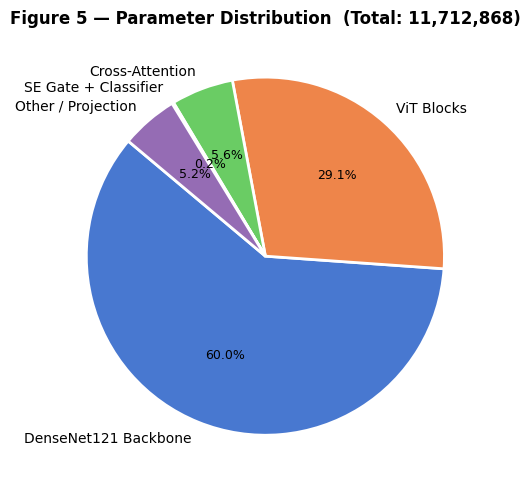

In [15]:
# ── Figure 5: Parameter Count by Submodule ────────────────────────────────────
submodule_params = {}
for layer in model.layers:
    n = sum([tf.size(w).numpy() for w in layer.weights])
    if n > 0:
        submodule_params[layer.name] = n

# Aggregate into logical groups
groups = {
    'DenseNet121 Backbone' : sum(v for k, v in submodule_params.items() if 'densenet' in k.lower() or 'dense_block' in k.lower() or 'conv' in k.lower()),
    'ViT Blocks'           : sum(v for k, v in submodule_params.items() if 'vit_block' in k.lower() or 'patch' in k.lower() or 'transformer' in k.lower()),
    'Cross-Attention'      : sum(v for k, v in submodule_params.items() if 'cross_attn' in k.lower() or 'cross_attention' in k.lower()),
    'SE Gate + Classifier' : sum(v for k, v in submodule_params.items() if 'se_gate' in k.lower() or 'class_output' in k.lower()),
    'Other / Projection'   : sum(v for k, v in submodule_params.items()),   # catch-all
}
# Ensure no double counting: subtract already-counted from 'Other'
counted = sum(list(groups.values())[:-1])
groups['Other / Projection'] = max(0, model.count_params() - counted)

fig, ax = plt.subplots(figsize=(9, 5))
colors  = sns.color_palette('muted', len(groups))
wedges, texts, autotexts = ax.pie(
    groups.values(), labels=groups.keys(), autopct='%1.1f%%',
    colors=colors, startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(9)
ax.set_title(
    f'Figure 5 — Parameter Distribution  (Total: {model.count_params():,})',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('fig5_param_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Compile & Callbacks

In [16]:
# model.compile(
#     optimizer=keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=1e-5),
#     loss='sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )


import tensorflow_addons as tfa

optimizer = tfa.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=1e-5
)

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
callbacks = [
    EarlyStopping(
        monitor='val_loss', patience=8,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=4, min_lr=1e-7, verbose=1
    ),
    # ModelCheckpoint(
    #     CHECKPOINT_PATH, monitor='val_accuracy',
    #     save_best_only=True, verbose=1
    # ),
    ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    verbose=1
    ),
]

print("Model compiled ✓")

Model compiled ✓


## 9. Phase 1 — Frozen Backbone Training

In [17]:
# Phase 1: DenseNet frozen — only ViT + fusion head trains
densenet_base.trainable = False

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS // 2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
1750/1750 [==============================] - ETA: 0s - loss: 1.2018 - accuracy: 0.4395
Epoch 1: val_accuracy improved from -inf to 0.50869, saving model to best_model.h5
1750/1750 [==============================] - 292s 158ms/step - loss: 1.2018 - accuracy: 0.4395 - val_loss: 1.0933 - val_accuracy: 0.5087 - lr: 1.0000e-04
Epoch 2/25
1750/1750 [==============================] - ETA: 0s - loss: 1.0502 - accuracy: 0.5422
Epoch 2: val_accuracy improved from 0.50869 to 0.59568, saving model to best_model.h5
1750/1750 [==============================] - 274s 157ms/step - loss: 1.0502 - accuracy: 0.5422 - val_loss: 0.9637 - val_accuracy: 0.5957 - lr: 1.0000e-04
Epoch 3/25
1750/1750 [==============================] - ETA: 0s - loss: 0.9291 - accuracy: 0.6140
Epoch 3: val_accuracy improved from 0.59568 to 0.66092, saving model to best_model.h5
1750/1750 [==============================] - 280s 160ms/step - loss: 0.9291 - accuracy: 0.6140 - val_loss: 0.8316 - val_accuracy: 0.6609 - lr: 

## 10. Phase 2 — Fine-tuning (Unfreeze DenseNet top layers)

In [18]:
# Unfreeze last 50 layers of DenseNet121 for fine-tuning
densenet_base.trainable = True
for layer in densenet_base.layers[:-50]:
    layer.trainable = False

trainable_count = sum(1 for l in densenet_base.layers if l.trainable)
print(f"DenseNet layers unfrozen for fine-tuning: {trainable_count}")

model.compile(
    optimizer=tfa.optimizers.AdamW(learning_rate=LEARNING_RATE / 10, weight_decay=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    initial_epoch=len(history_phase1.history['loss']),
    callbacks=callbacks,
    verbose=1
)

DenseNet layers unfrozen for fine-tuning: 50
Epoch 26/50
1750/1750 [==============================] - ETA: 0s - loss: 0.6462 - accuracy: 0.7521
Epoch 26: val_accuracy did not improve from 0.93688
1750/1750 [==============================] - 292s 160ms/step - loss: 0.6462 - accuracy: 0.7521 - val_loss: 0.3380 - val_accuracy: 0.8776 - lr: 1.0000e-05
Epoch 27/50
1750/1750 [==============================] - ETA: 0s - loss: 0.3518 - accuracy: 0.8712
Epoch 27: val_accuracy did not improve from 0.93688
1750/1750 [==============================] - 277s 158ms/step - loss: 0.3518 - accuracy: 0.8712 - val_loss: 0.2482 - val_accuracy: 0.9115 - lr: 1.0000e-05
Epoch 28/50
1750/1750 [==============================] - ETA: 0s - loss: 0.2721 - accuracy: 0.9044
Epoch 28: val_accuracy did not improve from 0.93688
1750/1750 [==============================] - 277s 158ms/step - loss: 0.2721 - accuracy: 0.9044 - val_loss: 0.2050 - val_accuracy: 0.9285 - lr: 1.0000e-05
Epoch 29/50
1750/1750 [=================

## 11. Training Visualisations

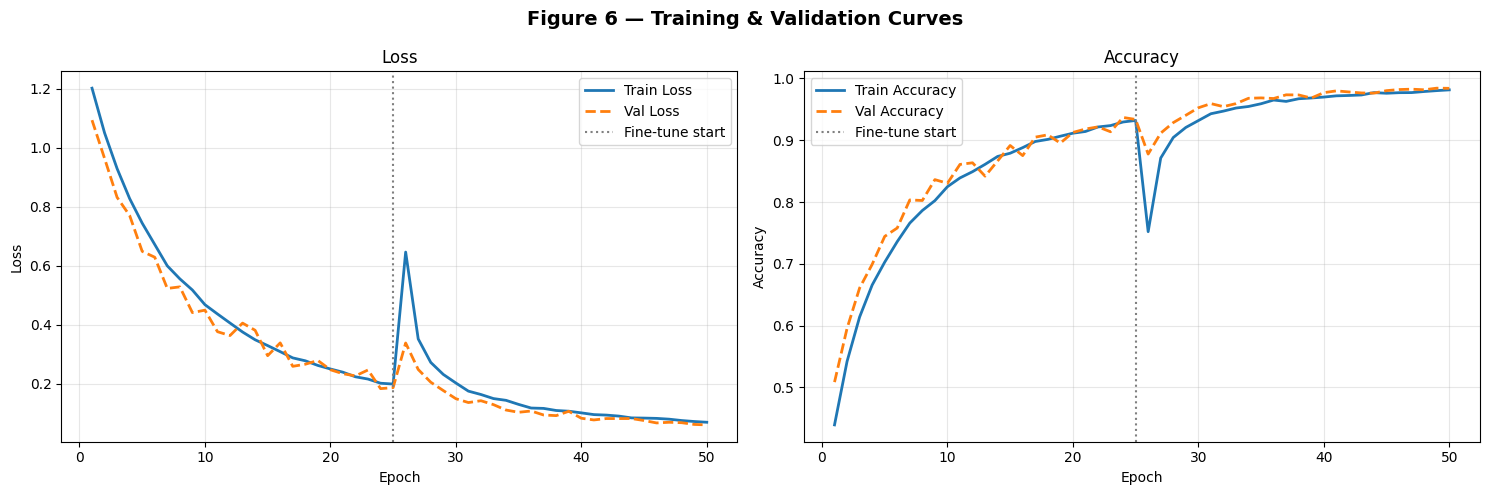

In [19]:
# Merge histories
def merge_histories(h1, h2):
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history[key]
    return merged

hist = merge_histories(history_phase1, history_phase2)
phase1_len = len(history_phase1.history['loss'])
total_len  = len(hist['loss'])
epochs_arr = range(1, total_len + 1)

# ── Figure 6: Training Curves ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Figure 6 — Training & Validation Curves', fontsize=14, fontweight='bold')

for ax, metric, label in zip(
    axes,
    ['loss',     'accuracy'],
    ['Loss',     'Accuracy']
):
    ax.plot(epochs_arr, hist[metric],     label=f'Train {label}', linewidth=2)
    ax.plot(epochs_arr, hist[f'val_{metric}'], label=f'Val {label}',   linewidth=2, linestyle='--')
    ax.axvline(phase1_len, color='gray', linestyle=':', linewidth=1.5, label='Fine-tune start')
    ax.set_title(label, fontsize=12)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(label)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig6_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

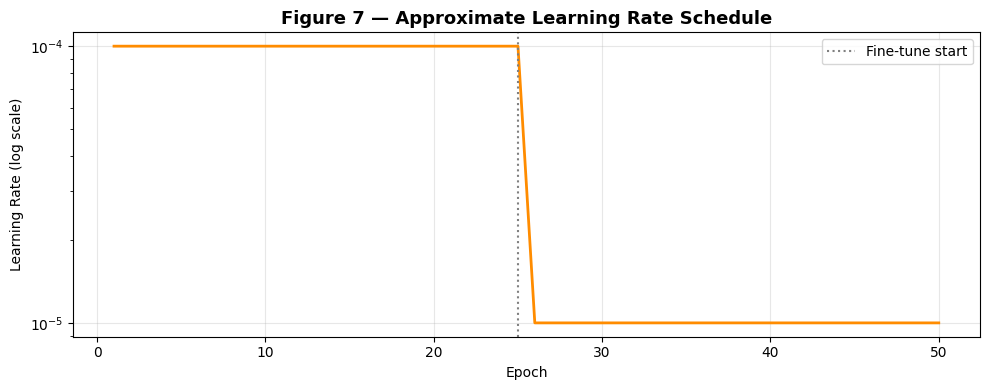

In [20]:
# ── Figure 7: Learning Rate Schedule ──────────────────────────────────────────
# Approximate LR from ReduceLROnPlateau callback
if hasattr(callbacks[1], 'history'):
    lr_hist = callbacks[1].history
else:
    lr_hist = [LEARNING_RATE] * phase1_len + [LEARNING_RATE / 10] * (total_len - phase1_len)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(epochs_arr, lr_hist[:total_len], color='darkorange', linewidth=2)
ax.axvline(phase1_len, color='gray', linestyle=':', linewidth=1.5, label='Fine-tune start')
ax.set_title('Figure 7 — Approximate Learning Rate Schedule', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Learning Rate (log scale)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig7_lr_schedule.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Evaluation on Test Set

In [21]:
# ── Gather predictions ────────────────────────────────────────────────────────
y_pred_prob = model.predict(test_ds, verbose=1)   # (N, num_classes)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = y_test.copy()

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"\n{'='*50}")
print(f"Test Accuracy : {test_acc * 100:.2f} %")
print(f"Test Loss     : {test_loss:.4f}")
print(f"{'='*50}")

250/250 [==============================] - 22s 78ms/step

Test Accuracy : 98.65 %
Test Loss     : 0.0549


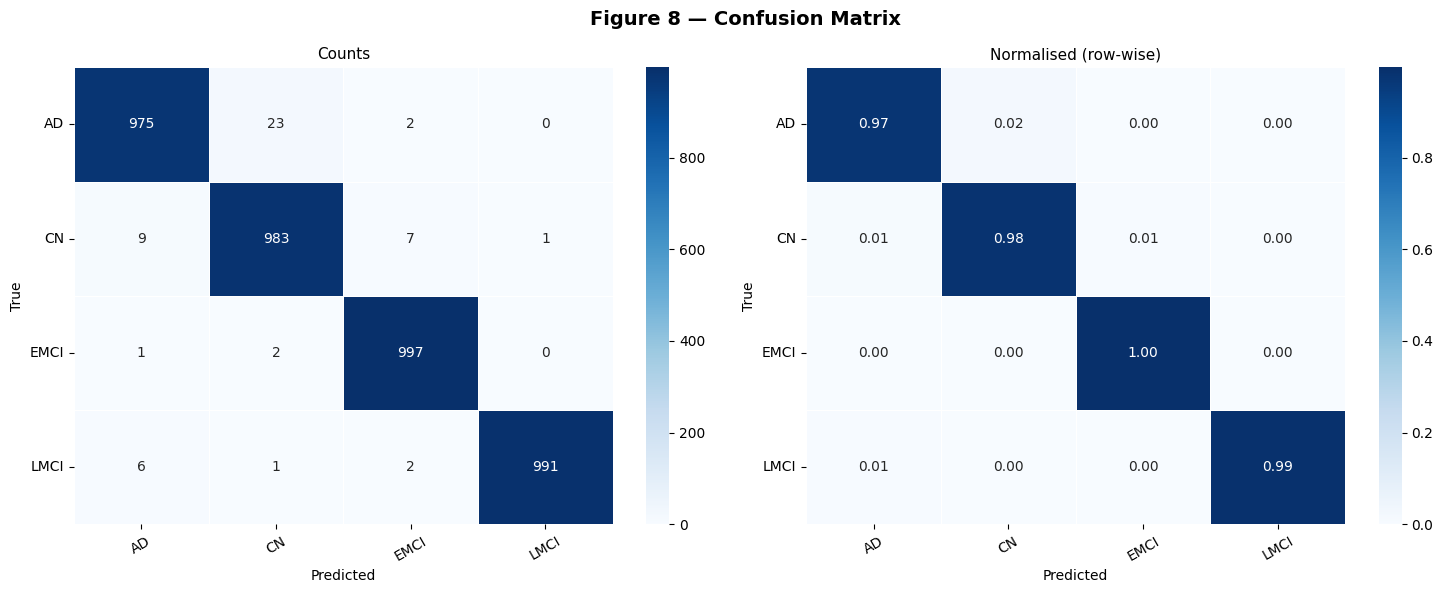

In [22]:
# ── Figure 8: Confusion Matrix ────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Figure 8 — Confusion Matrix', fontsize=14, fontweight='bold')

for ax, data, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ['d', '.2f'],
    ['Counts', 'Normalised (row-wise)']
):
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap='Blues',
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        ax=ax, linewidths=0.5
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('True', fontsize=10)
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('fig8_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

              precision    recall  f1-score   support

          AD       0.98      0.97      0.98      1000
          CN       0.97      0.98      0.98      1000
        EMCI       0.99      1.00      0.99      1000
        LMCI       1.00      0.99      0.99      1000

    accuracy                           0.99      4000
   macro avg       0.99      0.99      0.99      4000
weighted avg       0.99      0.99      0.99      4000



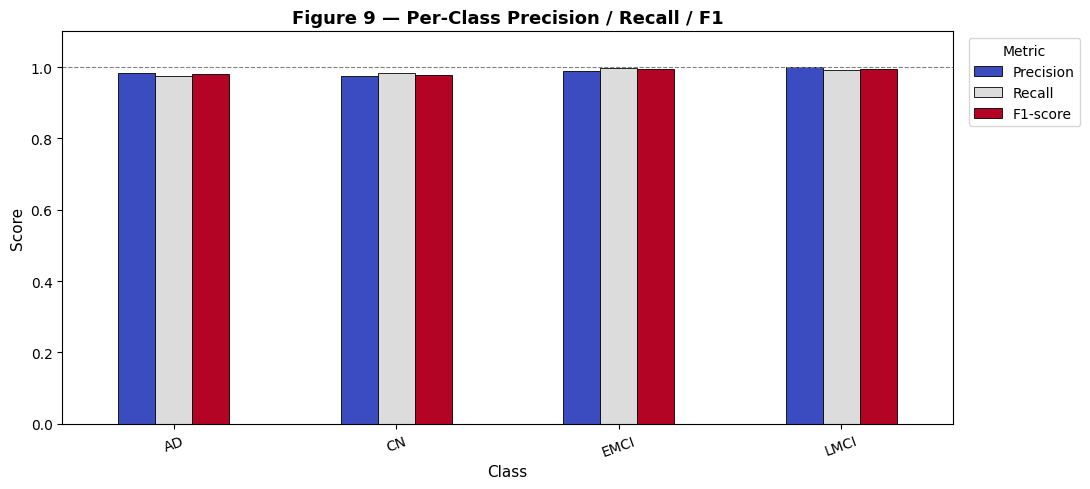

In [23]:
# ── Figure 9: Per-Class Metrics Bar Chart ─────────────────────────────────────
report = classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

metrics_df = pd.DataFrame({
    cls: {
        'Precision': report[cls]['precision'],
        'Recall'   : report[cls]['recall'],
        'F1-score' : report[cls]['f1-score'],
    }
    for cls in CLASS_NAMES
}).T

fig, ax = plt.subplots(figsize=(11, 5))
metrics_df.plot(kind='bar', ax=ax, colormap='coolwarm', edgecolor='black', linewidth=0.6)
ax.set_title('Figure 9 — Per-Class Precision / Recall / F1', fontsize=13, fontweight='bold')
ax.set_xlabel('Class', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0, 1.1)
ax.tick_params(axis='x', rotation=20)
ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8)
ax.legend(title='Metric', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig('fig9_per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

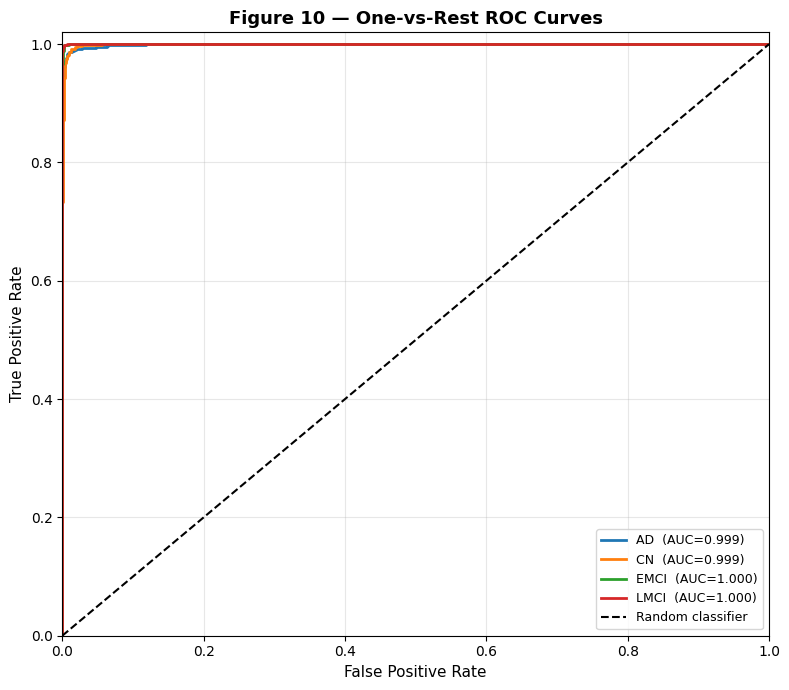

In [24]:
# ── Figure 10: One-vs-Rest ROC Curves ─────────────────────────────────────────
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(8, 7))
colors  = sns.color_palette('tab10', NUM_CLASSES)

for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=col, lw=2, label=f'{cls}  (AUC={roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random classifier')
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('Figure 10 — One-vs-Rest ROC Curves', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig10_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

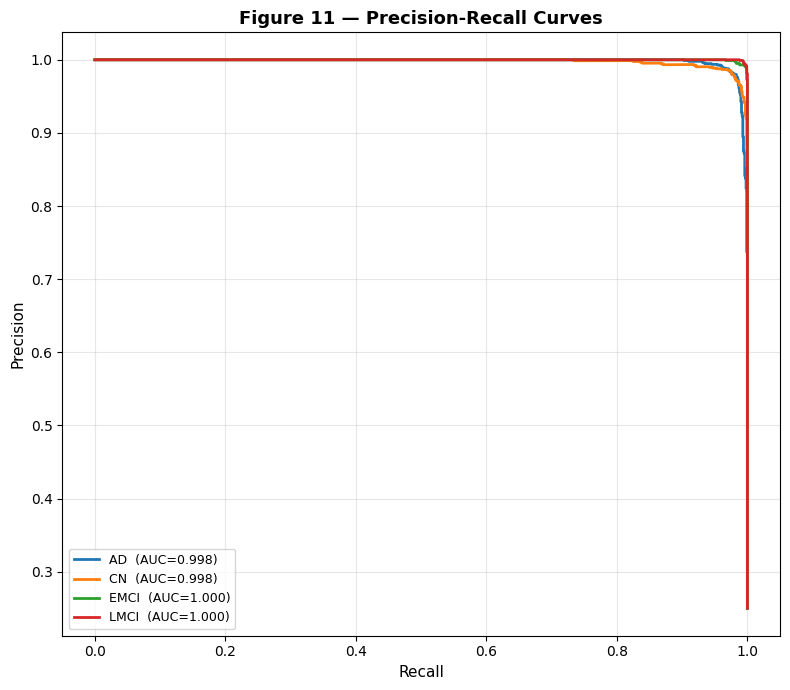

In [26]:
# ── Figure 11: Precision-Recall Curves ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))

for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
    prec, rec, _ = precision_recall_curve(y_true_bin[:, i], y_pred_prob[:, i])
    pr_auc       = auc(rec, prec)
    ax.plot(rec, prec, color=col, lw=2, label=f'{cls}  (AUC={pr_auc:.3f})')

ax.set_xlabel('Recall', fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.set_title('Figure 11 — Precision-Recall Curves', fontsize=13, fontweight='bold')
ax.legend(loc='lower left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig11_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

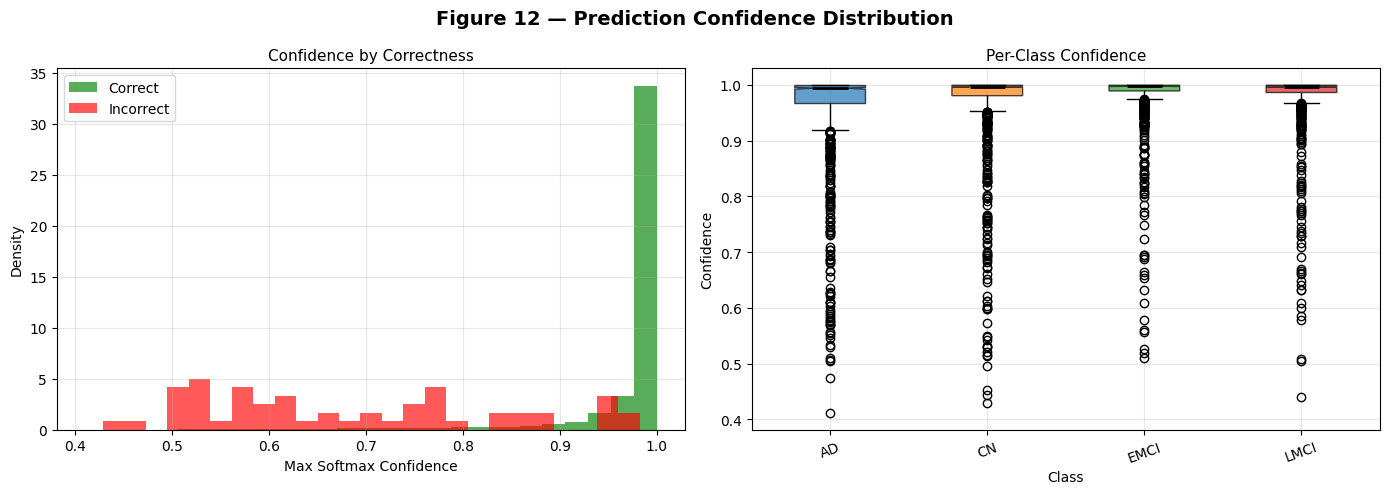

In [27]:
# ── Figure 12: Prediction Confidence Distribution ─────────────────────────────
confidences = np.max(y_pred_prob, axis=1)
correct     = (y_pred == y_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Figure 12 — Prediction Confidence Distribution', fontsize=14, fontweight='bold')

# Overall confidence KDE
axes[0].hist(confidences[correct],  bins=25, alpha=0.65, color='green', label='Correct',   density=True)
axes[0].hist(confidences[~correct], bins=25, alpha=0.65, color='red',   label='Incorrect', density=True)
axes[0].set_title('Confidence by Correctness', fontsize=11)
axes[0].set_xlabel('Max Softmax Confidence')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Per-class confidence box plots
class_confidences = [confidences[y_true == i] for i in range(NUM_CLASSES)]
bp = axes[1].boxplot(class_confidences, labels=CLASS_NAMES, patch_artist=True,
                     notch=True, medianprops=dict(color='black', linewidth=2))
for patch, col in zip(bp['boxes'], colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.7)
axes[1].set_title('Per-Class Confidence', fontsize=11)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Confidence')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig12_confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

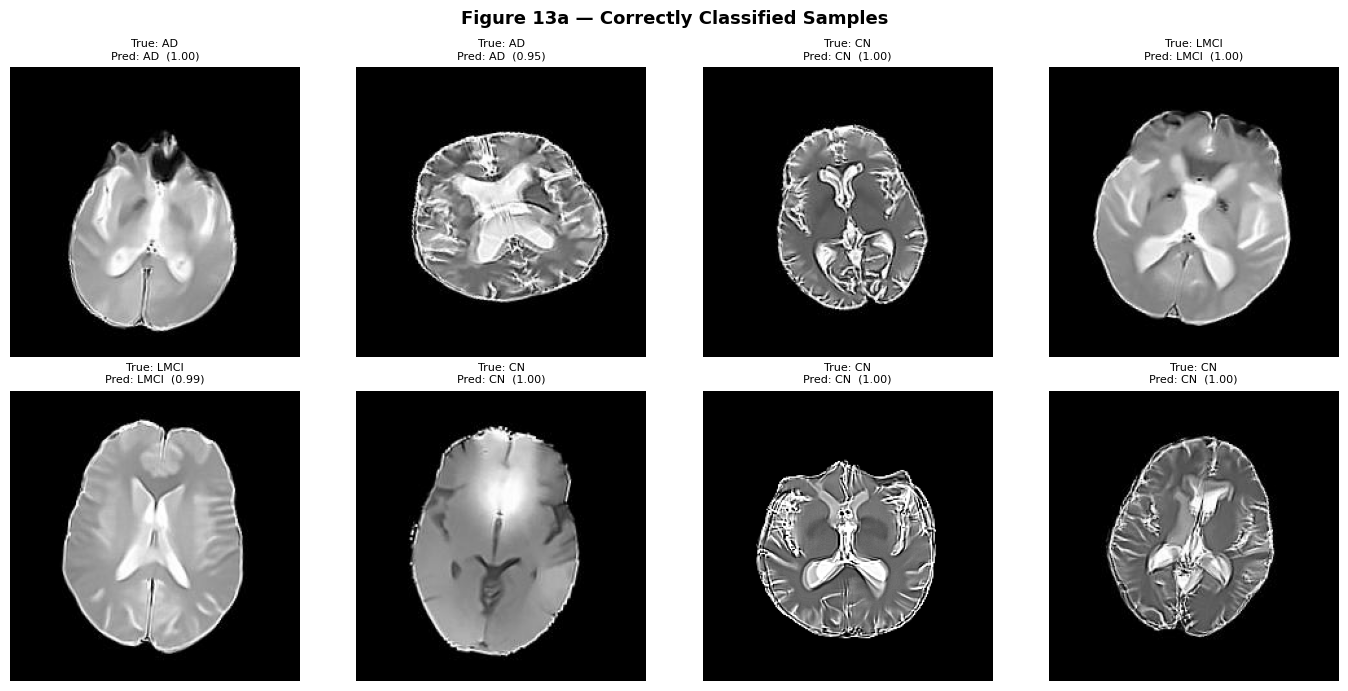

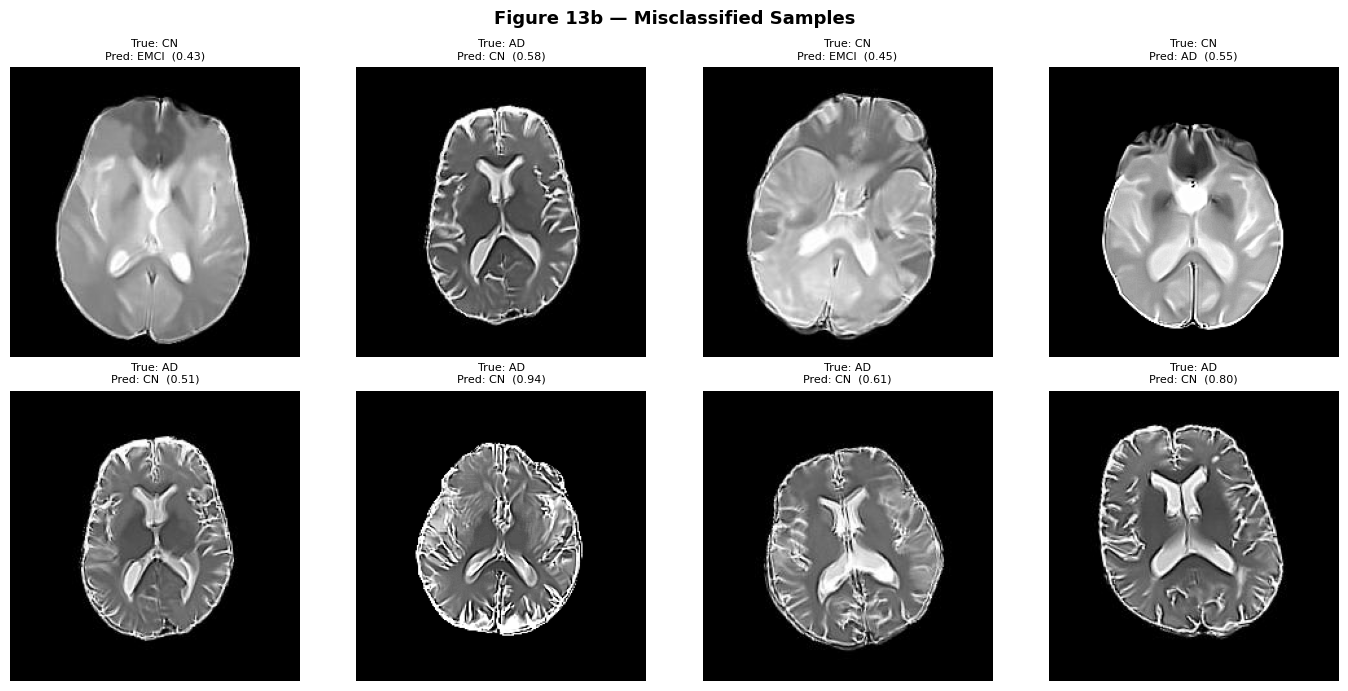

In [28]:
# ── Figure 13: Correct vs Incorrect Sample Grid ───────────────────────────────
from tensorflow.keras.preprocessing.image import load_img

def show_prediction_grid(title, mask, n=8):
    indices = np.where(mask)[0]
    selected = np.random.choice(indices, min(n, len(indices)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    fig.suptitle(title, fontsize=13, fontweight='bold')
    for ax, idx in zip(axes.flat, selected):
        img = load_img(X_test[idx], target_size=IMG_SIZE)
        ax.imshow(img)
        conf = confidences[idx]
        ax.set_title(
            f'True: {CLASS_NAMES[y_true[idx]]}\n'
            f'Pred: {CLASS_NAMES[y_pred[idx]]}  ({conf:.2f})',
            fontsize=8
        )
        ax.axis('off')
    for ax in axes.flat[len(selected):]:
        ax.axis('off')
    plt.tight_layout()
    return fig

fig13a = show_prediction_grid('Figure 13a — Correctly Classified Samples',  correct)
fig13a.savefig('fig13a_correct_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

if (~correct).sum() > 0:
    fig13b = show_prediction_grid('Figure 13b — Misclassified Samples', ~correct)
    fig13b.savefig('fig13b_wrong_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()

## 13. Grad-CAM Visualisation

In [29]:
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    Computes a Grad-CAM saliency map for `img_array` w.r.t.
    the convolutional layer named `last_conv_layer_name`.

    Parameters
    ----------
    img_array           : np.ndarray  shape (1, H, W, 3)
    model               : keras Model
    last_conv_layer_name: str
    pred_index          : int or None  — if None uses argmax

    Returns
    -------
    heatmap : np.ndarray  shape (h, w)  values in [0, 1]
    """
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads    = tape.gradient(class_channel, conv_outputs)
    pooled   = tf.reduce_mean(grads, axis=(0, 1, 2))        # (C,)
    cam      = conv_outputs[0] @ pooled[..., tf.newaxis]    # (H, W, 1)
    cam      = tf.squeeze(cam)
    cam      = tf.maximum(cam, 0) / (tf.math.reduce_max(cam) + 1e-8)
    return cam.numpy()


# Find the last conv layer of DenseNet121
last_conv_name = None
for layer in reversed(densenet_base.layers):
    if isinstance(layer, layers.Conv2D):
        last_conv_name = layer.name
        break
print(f"Last conv layer for Grad-CAM: {last_conv_name}")

Last conv layer for Grad-CAM: conv5_block16_2_conv


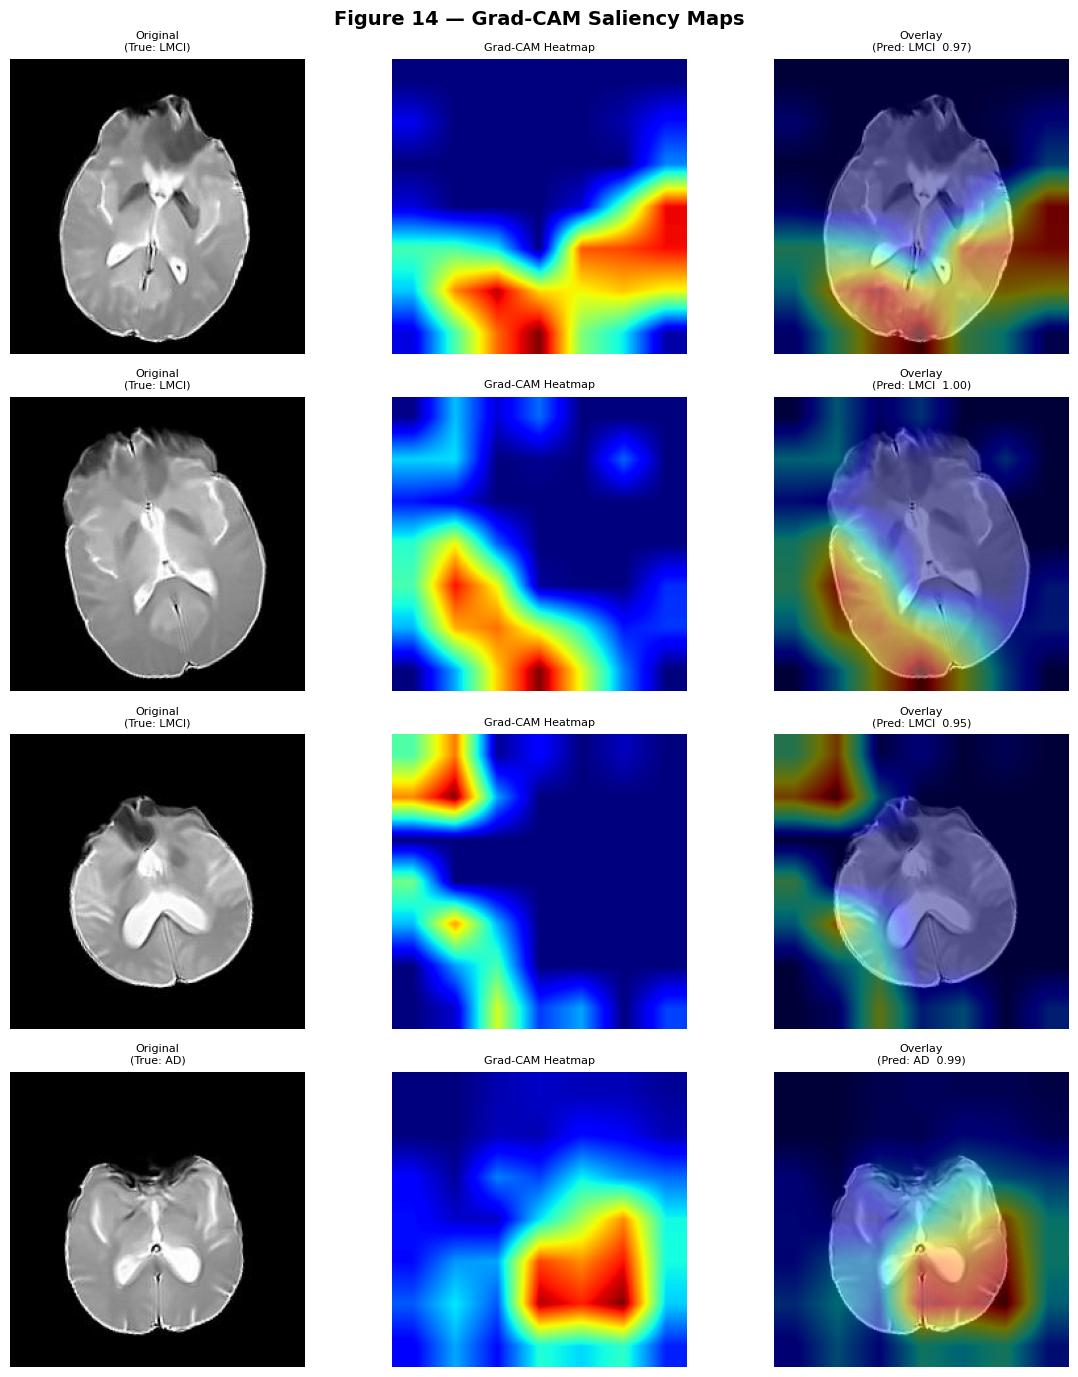

In [30]:
# ── Figure 14: Grad-CAM Heatmaps ─────────────────────────────────────────────
N_GRADCAM = 4
sample_idx = np.random.choice(len(X_test), N_GRADCAM, replace=False)

fig, axes = plt.subplots(N_GRADCAM, 3, figsize=(12, N_GRADCAM * 3.5))
fig.suptitle('Figure 14 — Grad-CAM Saliency Maps', fontsize=14, fontweight='bold')

for row, idx in enumerate(sample_idx):
    orig_img = np.array(load_img(X_test[idx], target_size=IMG_SIZE)) / 255.0
    inp      = orig_img[np.newaxis].astype('float32')

    try:
        heatmap = make_gradcam_heatmap(inp, model, last_conv_name)
        heatmap_resized = cv2.resize(heatmap, IMG_SIZE[::-1])
        heatmap_color   = plt.cm.jet(heatmap_resized)[..., :3]
        overlay         = 0.55 * orig_img + 0.45 * heatmap_color
        overlay         = np.clip(overlay, 0, 1)
    except Exception:
        heatmap_resized = np.zeros(IMG_SIZE)
        overlay         = orig_img

    axes[row, 0].imshow(orig_img)
    axes[row, 0].set_title(f'Original\n(True: {CLASS_NAMES[y_true[idx]]})', fontsize=8)
    axes[row, 0].axis('off')

    im = axes[row, 1].imshow(heatmap_resized, cmap='jet', vmin=0, vmax=1)
    axes[row, 1].set_title('Grad-CAM Heatmap', fontsize=8)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f'Overlay\n(Pred: {CLASS_NAMES[y_pred[idx]]}  {confidences[idx]:.2f})', fontsize=8)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('fig14_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Feature Space Visualisation (t-SNE)

Feature matrix shape: (4000, 256)


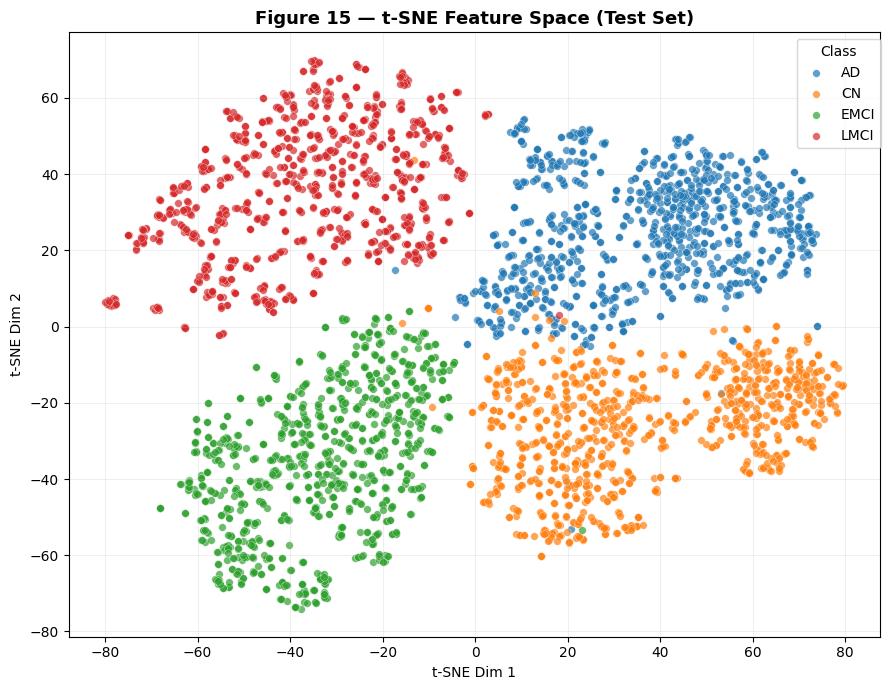

In [31]:
from sklearn.manifold import TSNE

# Build feature extractor (up to SE gate output)
feat_extractor = Model(
    inputs=model.input,
    outputs=model.get_layer('se_gate').output,
    name='feature_extractor'
)

# Extract features from test set
feats_list, labels_list = [], []
for batch_imgs, batch_labels in test_ds:
    feats_list.append(feat_extractor(batch_imgs, training=False).numpy())
    labels_list.append(batch_labels.numpy())

feats  = np.concatenate(feats_list,  axis=0)
labels = np.concatenate(labels_list, axis=0)

print(f"Feature matrix shape: {feats.shape}")

# t-SNE
tsne       = TSNE(n_components=2, random_state=SEED, perplexity=min(30, len(feats) - 1))
feats_2d   = tsne.fit_transform(feats)

# ── Figure 15: t-SNE Embedding ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
    mask = labels == i
    ax.scatter(feats_2d[mask, 0], feats_2d[mask, 1],
               c=[col], label=cls, alpha=0.7, s=30, edgecolors='white', linewidths=0.3)

ax.set_title('Figure 15 — t-SNE Feature Space (Test Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('t-SNE Dim 1')
ax.set_ylabel('t-SNE Dim 2')
ax.legend(title='Class', bbox_to_anchor=(1.01, 1))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('fig15_tsne.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Summary Dashboard

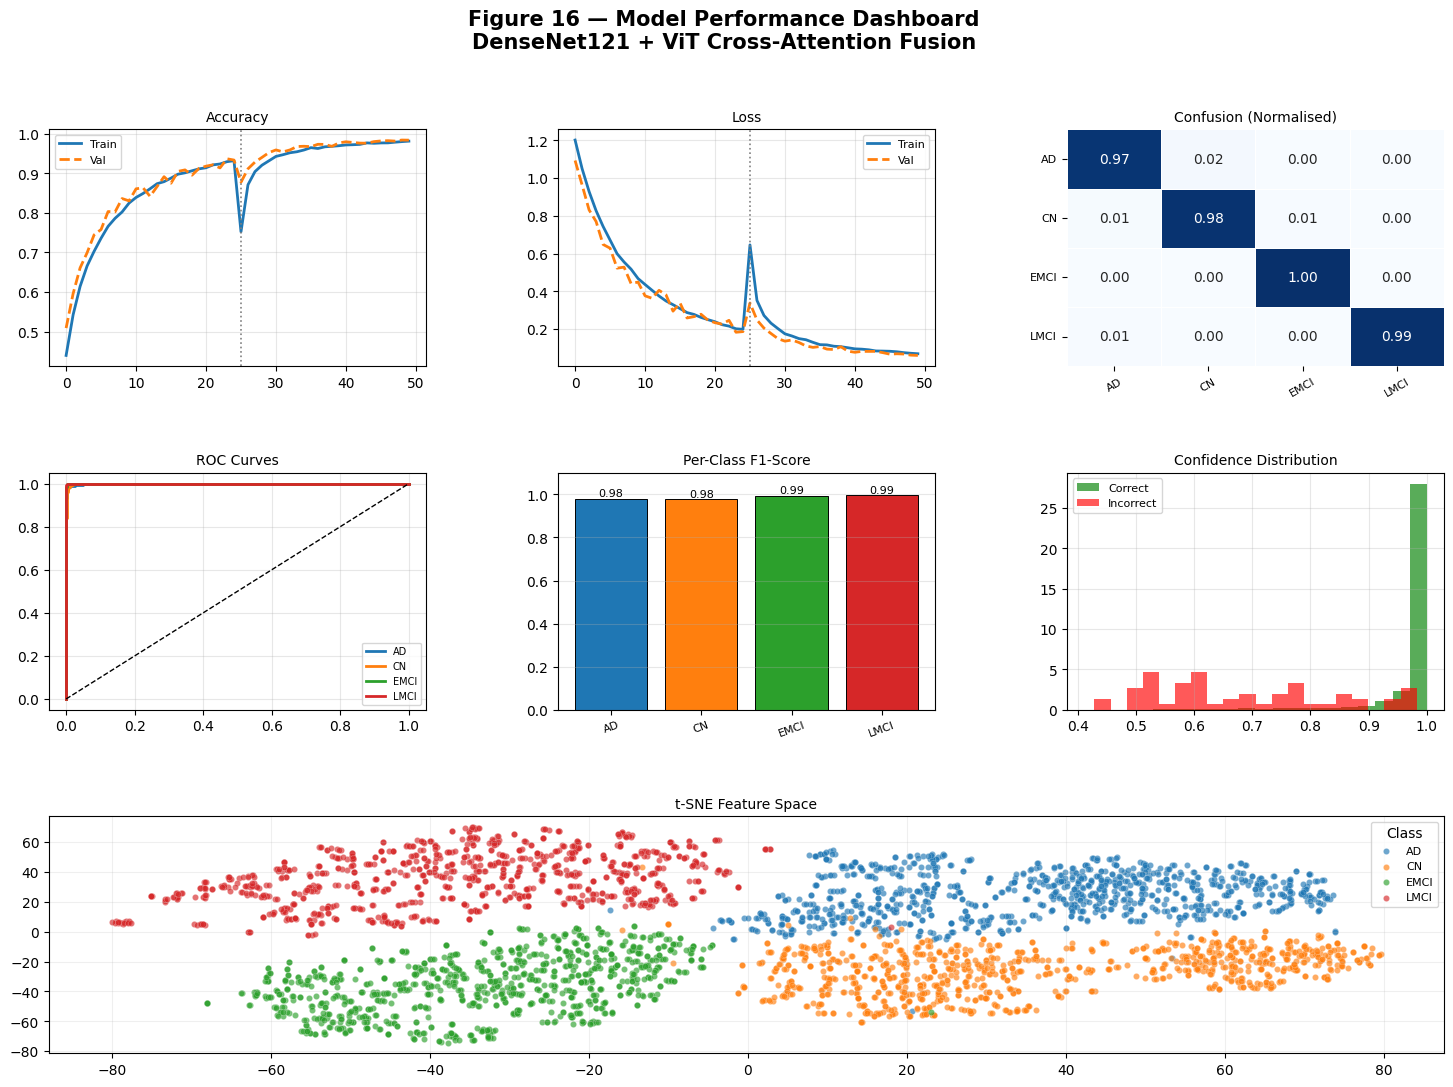

In [32]:
# ── Figure 16: Final Summary Dashboard ───────────────────────────────────────
fig = plt.figure(figsize=(18, 12))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle(
    'Figure 16 — Model Performance Dashboard\n'
    'DenseNet121 + ViT Cross-Attention Fusion',
    fontsize=15, fontweight='bold'
)

# (a) Training accuracy
ax_acc = fig.add_subplot(gs[0, 0])
ax_acc.plot(hist['accuracy'],     label='Train', lw=2)
ax_acc.plot(hist['val_accuracy'], label='Val',   lw=2, linestyle='--')
ax_acc.axvline(phase1_len, color='gray', linestyle=':', lw=1.2)
ax_acc.set_title('Accuracy', fontsize=10)
ax_acc.legend(fontsize=8); ax_acc.grid(alpha=0.3)

# (b) Training loss
ax_loss = fig.add_subplot(gs[0, 1])
ax_loss.plot(hist['loss'],     label='Train', lw=2)
ax_loss.plot(hist['val_loss'], label='Val',   lw=2, linestyle='--')
ax_loss.axvline(phase1_len, color='gray', linestyle=':', lw=1.2)
ax_loss.set_title('Loss', fontsize=10)
ax_loss.legend(fontsize=8); ax_loss.grid(alpha=0.3)

# (c) Confusion matrix (normalised)
ax_cm = fig.add_subplot(gs[0, 2])
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=ax_cm, linewidths=0.4, cbar=False)
ax_cm.set_title('Confusion (Normalised)', fontsize=10)
ax_cm.tick_params(axis='x', rotation=30, labelsize=8)
ax_cm.tick_params(axis='y', rotation=0,  labelsize=8)

# (d) ROC
ax_roc = fig.add_subplot(gs[1, 0])
for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    ax_roc.plot(fpr, tpr, color=col, lw=2, label=f'{cls}')
ax_roc.plot([0,1],[0,1],'k--',lw=1)
ax_roc.set_title('ROC Curves', fontsize=10)
ax_roc.legend(fontsize=7, loc='lower right'); ax_roc.grid(alpha=0.3)

# (e) Per-class F1
ax_f1 = fig.add_subplot(gs[1, 1])
f1s   = [report[cls]['f1-score'] for cls in CLASS_NAMES]
bars  = ax_f1.bar(CLASS_NAMES, f1s, color=colors, edgecolor='black', linewidth=0.7)
ax_f1.set_ylim(0, 1.1)
ax_f1.set_title('Per-Class F1-Score', fontsize=10)
ax_f1.tick_params(axis='x', rotation=20, labelsize=8)
ax_f1.grid(alpha=0.3, axis='y')
for bar, val in zip(bars, f1s):
    ax_f1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
               f'{val:.2f}', ha='center', fontsize=8)

# (f) Confidence histogram
ax_conf = fig.add_subplot(gs[1, 2])
ax_conf.hist(confidences[correct],  bins=20, alpha=0.65, color='green', label='Correct',   density=True)
ax_conf.hist(confidences[~correct], bins=20, alpha=0.65, color='red',   label='Incorrect', density=True)
ax_conf.set_title('Confidence Distribution', fontsize=10)
ax_conf.legend(fontsize=8); ax_conf.grid(alpha=0.3)

# (g) t-SNE
ax_tsne = fig.add_subplot(gs[2, :])
for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
    mask = labels == i
    ax_tsne.scatter(feats_2d[mask, 0], feats_2d[mask, 1],
                    c=[col], label=cls, alpha=0.65, s=20, edgecolors='white', linewidths=0.2)
ax_tsne.set_title('t-SNE Feature Space', fontsize=10)
ax_tsne.legend(title='Class', fontsize=8, loc='upper right')
ax_tsne.grid(alpha=0.2)

plt.savefig('fig16_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## 16. Save Model & Export

In [34]:
# ── Save full model ───────────────────────────────────────────────────────────
model.save('densenet_vit_fusion_final.h5')
print("Model saved to  densenet_vit_fusion_final.keras")

# ── Print final summary ───────────────────────────────────────────────────────
print("\n" + "="*60)
print("  FINAL RESULTS SUMMARY")
print("="*60)
print(f"  Test Accuracy          : {test_acc * 100:.2f} %")
print(f"  Test Loss              : {test_loss:.4f}")
print(f"  Macro Avg F1           : {report['macro avg']['f1-score']:.4f}")
print(f"  Weighted Avg F1        : {report['weighted avg']['f1-score']:.4f}")
print(f"  Total Parameters       : {model.count_params():,}")
print(f"  Trainable Parameters   : {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")
print("="*60)

print("\nFigures saved:")
figures = [
    'fig1_class_distribution.png',
    'fig2_sample_images.png',
    'fig3_split_distribution.png',
    'fig4_augmentation.png',
    'fig5_param_distribution.png',
    'fig6_training_curves.png',
    'fig7_lr_schedule.png',
    'fig8_confusion_matrix.png',
    'fig9_per_class_metrics.png',
    'fig10_roc_curves.png',
    'fig11_pr_curves.png',
    'fig12_confidence_distribution.png',
    'fig13a_correct_predictions.png',
    'fig13b_wrong_predictions.png',
    'fig14_gradcam.png',
    'fig15_tsne.png',
    'fig16_dashboard.png',
]
for f in figures:
    print(f"  ✓ {f}")

NotImplementedError: 
Layer SEFeatureGate has arguments ['units', 'ratio']
in `__init__` and therefore must override `get_config()`.

Example:

class CustomLayer(keras.layers.Layer):
    def __init__(self, arg1, arg2):
        super().__init__()
        self.arg1 = arg1
        self.arg2 = arg2

    def get_config(self):
        config = super().get_config()
        config.update({
            "arg1": self.arg1,
            "arg2": self.arg2,
        })
        return config